# Tutorial 18: Magnetic states at the Co absorption peak

Generate magnetic-state measurements at one fixed energy. The editable
`state_specs` list controls the number of saturated, skyrmion, and labyrinth
states; previews validate against the saved run manifest.
Geometry, illumination, energy, and detector settings follow Tutorial 12 and remain
fixed. Saturated repeats have identical magnetization but independent detector noise.
The skyrmions are scalar out-of-plane textures, with the same teaching convention
for the in-plane component as Tutorial 12; these are not micromagnetic equilibria.

Each state is streamed to its own HDF5 file in a new run directory under
`outputs/18_magnetic_state_dataset`. Full CR/CL detector frames, ideal images,
exit waves, XMCD, magnetic ground truth, parameters, and support masks are saved.
Previous runs are preserved. Run all cells to generate the dataset; this can take
several minutes per state at the default 2048×2048 sample grid.

In [5]:
import gc
import sys
from pathlib import Path
from types import SimpleNamespace

# Make the repository's src-layout packages importable without installing them.
repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "scattering_calculator").is_dir()),
    None,
)
if repo_root is None:
    raise RuntimeError("Could not find src/scattering_calculator above the notebook working directory")
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import numpy as np
import h5py
import matplotlib.pyplot as plt

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
plt.rcParams["figure.constrained_layout.use"] = True

from scattering_calculator.sample_generator import pattern_generator
from scattering_calculator.simulation_pipelines import simulation_configuration as sim
import json
from datetime import datetime, timezone
from uuid import uuid4

## Fixed experimental controls
The default energy is the maximum tabulated **nonmagnetic Co beta in the L3
window (775–785 eV)**. It is computed from the repository optical constants,
not assumed from a nominal edge position. `ENERGY_OVERRIDE_EV` allows a calibrated
peak energy. All states and both helicities use the selected energy.

In [6]:
RUN_DATASET = True
OUTPUT_ROOT = repo_root / "outputs" / "18_magnetic_state_dataset"
ENERGY_OVERRIDE_EV = None
co_beta_path = repo_root / "src/scattering_calculator/database/material_parameter/refractive_indexes/Co/Co_beta.txt"
co_beta = np.loadtxt(co_beta_path)
l3 = co_beta[(co_beta[:, 0] >= 775) & (co_beta[:, 0] <= 785)]
peak_energy_eV = float(l3[np.argmax(l3[:, 1]), 0])
energy_eV = peak_energy_eV if ENERGY_OVERRIDE_EV is None else float(ENERGY_OVERRIDE_EV)
reference_energy_eV = energy_eV
pols = ["CR", "CL"]
detector_propagation_method = "fraunhofer"
FIX_DETECTOR_PROJECTION_ENERGY = True
recipe = "[Au(500)/Cr(60)]x5/SiN(100)/Co(18)Pt(18)"
propagator_method = "Scalar"
scalar_refractive_index_lazy = True

# Jones-only is fast and already includes the rank-zero longitudinal phase.
# Set propagate=True to include multislice free-space propagation between layers.
propagate = True
jones_apply_zero_order_phase = True
multislice_propagation_roi = True
multislice_propagation_roi_padding_px = 15
multislice_propagation_roi_merge_overlaps = False
propagation_padding_px = 10
propagation_padding_mode = "edge"
propagation_absorber_width_px = 5
propagation_absorber_strength = 6.0
propagation_absorber_profile = "cosine"

# Detector and beam settings. The sample mesh is fixed from reference_energy_eV.
detector_shape = (1024,1024)
detector_center = tuple(np.array(detector_shape) // 2)
# oversampling=2 creates a 2048x2048 sample grid; oversampling=4 creates a
# 4096x4096 sample grid and can exceed RAM during a single energy point.
oversampling = 2
ignore_flat_detector_curvature = False
photon_flux = 5e8
coherence_length = (25000e-6, 25000e-6)

# Fixed sample, aperture, and illumination.


sample_name = "magnetic_state_dataset"
illumination_center = (0.0, 0.0)
illumination_focus_distance = 1e-3
illumination_fwhm = 50.e-6
illumination_alpha_beam = (0.0, 0.0)

aperture_types = ["OH", "RH", "RH"]
aperture_radii = [500e-9,  30e-9, 10e-9]
aperture_centers = [(0.0, 0.0), (-1200e-9, -1200e-9), (1200e-9, -1200e-9)]
aperture_sigmas = [4e-9, 2e-9, 2e-9]
aperture_angles = [0.0, 0.0,0]
aperture_ellipticities = [1.0, 1, 1.0]
aperture_roughnesses = [0.05,0.05, 0.05]#[0.02,0.02,0.02]
aperture_roughness_modes = [(3, 10),(3, 10), (3, 10)]#[(0, 0),(3, 10), (3, 10)]
aperture_seeds = [1,2, 4]
aperture_top_radius_factors = [1.1 , 5., 5.]

# The object image in an FTH reconstruction is not centered at the origin.
# It is displaced by the reference-hole/object-hole separation. Use the first
# RH by default; flip the sign if you want the conjugate/twin object image.
fth_reference_aperture_index = 1
fth_reconstruction_shift_sign = 1


print(f"Fixed energy: {energy_eV:.6f} eV; tabulated Co L3 beta peak: {peak_energy_eV:.6f} eV")

Fixed energy: 781.138660 eV; tabulated Co L3 beta peak: 781.138660 eV


## Mesh and state catalogue
Length parameters are in metres. Skyrmion settings vary diameter, wall width,
density, diameter spread, positional disorder, ellipticity, roughness, and seed.
Skyrmion placement is restricted to the object hole so they appear in the image.
Labyrinth settings vary stripe width, smoothing, softness, evolution steps,
and seed, including the cobalt notebook's 135 nm stripe scale.

In [7]:
def make_xray_config(energy_eV, pol=pols[0]):
    xray_config = sim.XRayConfig(
        energy=float(energy_eV),
        photon_flux=photon_flux,
        pol=pol,
        coherence_length=coherence_length,
    )
    xray_config.setup()
    return xray_config


def make_detector_config(noise_seed=20):
    beamstop_config = sim.BeamstopConfig(
        bs_method="circular",
        bs_detector_distance=0.010,
        bs_center=detector_center,
        bs_config={
            "radius": 90e-6,
            "sigma": 1e-6,
            "wire_width": 5e-6,
            "wire_bend": 30e-6,
            "angle": np.deg2rad(25),
            "antialias": 2,
            "seed": 4,
        },
    )
    detector_config = sim.DetectorConfig(
        detector_propagation_method=detector_propagation_method,
        shape=detector_shape,
        pixel_size=20e-6,
        sample_to_detector_distance=0.10,
        detector_center=detector_center,
        detector_params={
            "readout_noise_average": 10,
            "readout_noise_sigma": 1,
            "detector_threshold": 64e3,
            "counts_per_photon": 200,
            "quantum_efficiency": 1.0,
            "noise_seed": int(noise_seed),
        },
        measurement_config={
            "number_frames": 50,
            # Accumulate photons and spread charge once; "per_frame" is slower.
            "acquisition_mode": "accumulated",
            "max_counts_per_image": 64e3,
            "exposure_time": 1.0,
        },
        beamstop_config=beamstop_config,
        use_detector_pixel_footprint=True,
        detector_pixel_footprint_samples=oversampling,
        ignore_flat_detector_curvature=(ignore_flat_detector_curvature if detector_propagation_method == "fraunhofer" else False),
    )
    detector_config.setup()
    return detector_config


reference_xray_config = make_xray_config(reference_energy_eV)
reference_detector_config = make_detector_config()
real_space_pixel_size = reference_detector_config.calc_realspace_resolution(reference_xray_config.beam_params) / oversampling
sample_shape = np.array([0, oversampling * detector_shape[0], oversampling * detector_shape[1]], dtype=int)


print(f"Sample grid: {tuple(sample_shape[1:])}; pixel: {real_space_pixel_size * 1e9:.3f} nm")
state_specs = []
for saturation, label in ((1.0, "plus"), (-1.0, "minus")):
    for repeat in range(2):
        state_specs.append({"name": f"saturated_{label}_{repeat + 1:02d}",
                            "family": "saturated", "pattern_type": "saturated_pattern",
                            "config": {"saturation": saturation}})
for i in range(3):
    diameter = (65 + 10 * i) * 1e-9
    state_specs.append({
        "name": f"skyrmion_{i + 1:02d}", "family": "skyrmion",
        "pattern_type": "disordered_skyrmion_lattice_pattern",
        "config": {"stripe_width": diameter, "sigma": (2 + i % 4 * 2) * 1e-9,
                   "skyrmion_density": 0.12 + 0.025 * i,
                   "diameter_spread": diameter * (0.05 + 0.02 * (i % 5)),
                   "ellipticity": [0.85 - 0.02 * (i % 4), 1.1 + 0.04 * (i % 4)],
                   "roughness": 0.02 + 0.01 * (i % 5), "roughness_modes": [3, 10],
                   "positional_disorder": (2 + 2 * i) * 1e-9,
                   "seed": 100 + i},
    })
for i, width_nm in enumerate((65, 80)):
    state_specs.append({
        "name": f"labyrinth_{i + 1:02d}", "family": "labyrinth",
        "pattern_type": "binary_labyrinth_pattern",
        "config": {"stripe_width": width_nm * 1e-9,
                   "sigma": (2 + i % 4 * 2) * 1e-9,
                   "domain_conversion": "soft", "softness": 0.8 + 0.1 * (i % 5),
                   "n_steps": 60 + 10 * (i % 3), "seed": 200 + i, "use_gpu": False},
    })
for spec in state_specs:
    print(spec["name"], spec["config"])

Sample grid: (np.int64(2048), np.int64(2048)); pixel: 3.899 nm
saturated_plus_01 {'saturation': 1.0}
saturated_plus_02 {'saturation': 1.0}
saturated_minus_01 {'saturation': -1.0}
saturated_minus_02 {'saturation': -1.0}
skyrmion_01 {'stripe_width': 6.5e-08, 'sigma': 2e-09, 'skyrmion_density': 0.12, 'diameter_spread': 3.25e-09, 'ellipticity': [0.85, 1.1], 'roughness': 0.02, 'roughness_modes': [3, 10], 'positional_disorder': 2e-09, 'placement_center': (np.float64(1024.0), np.float64(1024.0)), 'placement_radius': 6.15e-07, 'seed': 100}
skyrmion_02 {'stripe_width': 7.500000000000001e-08, 'sigma': 4e-09, 'skyrmion_density': 0.145, 'diameter_spread': 5.2500000000000015e-09, 'ellipticity': [0.83, 1.1400000000000001], 'roughness': 0.03, 'roughness_modes': [3, 10], 'positional_disorder': 4e-09, 'placement_center': (np.float64(1024.0), np.float64(1024.0)), 'placement_radius': 6.25e-07, 'seed': 101}
skyrmion_03 {'stripe_width': 8.500000000000001e-08, 'sigma': 6.000000000000001e-09, 'skyrmion_densi

## Simulation helpers
Use the same Scalar/Jones, multislice, aperture, illumination, and detector APIs as
Tutorial 12. The pattern is passed explicitly for each state. CR and CL use
independent, recorded noise seeds. Reconstructions are written one frame at a time.

In [8]:
def frame_average(array):
    if isinstance(array, h5py.Dataset) and array.ndim == 3:
        # Read one frame at a time, including when analysing older saved runs.
        mean = np.zeros(array.shape[1:], dtype=np.result_type(array.dtype, np.float64))
        for index in range(array.shape[0]):
            mean += array[index]
        return mean / array.shape[0]
    array = np.asarray(array)
    return array.mean(axis=0) if array.ndim == 3 else array

def fth_reconstruct(hologram):
    """Reconstruct over the spatial axes without shifting a frame axis."""
    axes = (-2, -1)
    return np.fft.fftshift(
        np.fft.fft2(np.fft.fftshift(hologram, axes=axes), axes=axes),
        axes=axes,
    )

def object_hole_crop_slices(shape, pixel_size, radius_factor=1.0):
    oh_index = aperture_types.index("OH")
    center_y_m, center_x_m = aperture_centers[oh_index]
    return crop_slices_around_position(shape, pixel_size, (center_y_m, center_x_m), aperture_radii[oh_index] * radius_factor)

def fth_object_image_crop_slices(shape, pixel_size, radius_factor=1.0):
    """Crop the FTH object image displaced by the selected RH-OH vector.

    In the exit wave the object hole is centered at its real-space OH position.
    In the FTH reconstruction, the object image appears in the cross-correlation
    term, shifted from the reconstruction origin by the reference-hole/object-hole
    separation. The sign selects which twin image to inspect.
    """
    oh_index = aperture_types.index("OH")
    oh_center = np.asarray(aperture_centers[oh_index], dtype=float)
    rh_center = np.asarray(aperture_centers[fth_reference_aperture_index], dtype=float)
    reconstruction_center = fth_reconstruction_shift_sign * (rh_center - oh_center)
    return crop_slices_around_position(
        shape,
        pixel_size,
        reconstruction_center,
        aperture_radii[oh_index] * radius_factor,
    )

def crop_slices_around_position(shape, pixel_size, center_m, radius_m):
    center_y_m, center_x_m = center_m
    cy = int(np.clip(round(shape[-2] / 2 + center_y_m / pixel_size), 0, shape[-2] - 1))
    cx = int(np.clip(round(shape[-1] / 2 + center_x_m / pixel_size), 0, shape[-1] - 1))
    half_width = max(4, int(np.ceil(radius_m / pixel_size)))
    y0 = max(0, cy - half_width)
    y1 = min(shape[-2], cy + half_width + 1)
    x0 = max(0, cx - half_width)
    x1 = min(shape[-1], cx + half_width + 1)
    return slice(y0, y1), slice(x0, x1)

def build_sample_and_aperture(xray_config, magnetic_pattern_2d):
    sample_config = sim.SampleConfig(
        recipe=recipe,
        sample_shape=sample_shape.copy(),
        real_space_pixel_size=real_space_pixel_size,
        xray_config=xray_config,
        sample_name=sample_name,
    )
    sample_config.setup()

    magnetization = pattern_generator.map_magnetization_to_3d(
        magnetic_pattern_x=np.zeros_like(magnetic_pattern_2d),
        magnetic_pattern_y=np.sqrt(np.clip(1 - np.abs(magnetic_pattern_2d) ** 2, 0, 1)),
        magnetic_pattern_z=magnetic_pattern_2d,
        nr_repeats=sample_config.sample_structure.sample_shape[0],
    )
    sample_config.assign_magnetic_pattern(magnetization)

    layer_thicknesses = sample_config.sample_structure.layer_thicknesses
    membrane_index = sample_config.sample_structure.layer_names.index("SiN")
    aperture_taper_depth = float(np.sum(layer_thicknesses[: max(0, membrane_index - 2)]))
    thickness_oh = float(np.sum(layer_thicknesses[:membrane_index]))

    aperture_config = sim.FrontApertureConfig(
        aperture_method="FTH_circular",
        aperture_shape=sample_config.sample_structure.sample_shape,
        real_space_pixel_size=real_space_pixel_size,
        aperture_thicknesses=layer_thicknesses,
        aperture_layer_names=sample_config.sample_structure.layer_names,
        use_roi=True,
        aperture_config={
            "apertures_type": aperture_types,
            "apertures_radius": aperture_radii,
            "apertures_center": aperture_centers,
            "apertures_sigma": aperture_sigmas,
            "apertures_angle": aperture_angles,
            "apertures_ellipticity": aperture_ellipticities,
            "apertures_roughness": aperture_roughnesses,
            "apertures_roughness_modes": aperture_roughness_modes,
            "apertures_seed": aperture_seeds,
            "apertures_top_radius_factor": aperture_top_radius_factors,
            "aperture_taper_depth": aperture_taper_depth,
            "thickness_OH": thickness_oh,
        },
    )
    aperture_config.setup()
    aperture_mask = aperture_config.return_aperture()
    sample_config.assign_aperture_mask(aperture_mask)

    if propagator_method == "Scalar":
        sample_config.sample_structure.calculate_final_scalar_refractive_index(
            pol=pols[0],
            use_aperture_roi=True,
            compact=True,
            lazy=scalar_refractive_index_lazy,
        )
    else:
        contrast_beam_direction = sim.light_beam.beam_direction_from_alpha(illumination_alpha_beam)
        if np.allclose(contrast_beam_direction, [0.0, 0.0, 1.0], atol=1e-14, rtol=0.0):
            contrast_beam_direction = None
        sample_config.sample_structure.calculate_final_dielectric_tensor(
            use_aperture_roi=True,
            compact=True if contrast_beam_direction is None else False,
            beam_direction=contrast_beam_direction,
        )
    return sample_config, aperture_config, aperture_mask

def make_illumination(xray_config):
    illumination_config = sim.IlluminationConfig(
        XRayConfig=xray_config,
        shape=tuple(sample_shape[1:]),
        real_space_pixel_size=real_space_pixel_size,
        illumination_function="gaussian",
        illumination_config={
            "center": np.array(illumination_center),
            "distance": illumination_focus_distance,
            "fwhm": illumination_fwhm,
            "alpha_beam": illumination_alpha_beam,
        },
    )
    illumination_config.setup()
    return illumination_config

def propagation_options(do_propagate):
    return {
        "propagate": do_propagate,
        "jones_apply_zero_order_phase": jones_apply_zero_order_phase,
        "scalar_apply_zero_order_phase": jones_apply_zero_order_phase,
        "scalar_refractive_index_lazy": scalar_refractive_index_lazy,
        "propagation_padding_px": propagation_padding_px,
        "propagation_padding_mode": propagation_padding_mode,
        "propagation_absorber_width_px": propagation_absorber_width_px,
        "propagation_absorber_strength": propagation_absorber_strength,
        "propagation_absorber_profile": propagation_absorber_profile,
        "multislice_propagation_roi": multislice_propagation_roi,
        "multislice_propagation_roi_padding_px": multislice_propagation_roi_padding_px,
        "multislice_propagation_roi_merge_overlaps": multislice_propagation_roi_merge_overlaps,
    }

def simulate_one_state(energy_eV, magnetic_pattern_2d, noise_seed_base=1000):
    xray_config = make_xray_config(energy_eV)
    detector_config = make_detector_config(noise_seed=noise_seed_base)
    projection_beam_params = (
        reference_xray_config.beam_params
        if FIX_DETECTOR_PROJECTION_ENERGY else xray_config.beam_params
    )
    detector_config.calc_realspace_resolution(projection_beam_params)
    sample_config, aperture_config, aperture_mask = build_sample_and_aperture(xray_config, magnetic_pattern_2d)

    illumination_config = make_illumination(xray_config)
    hologram_config = sim.HologramConfig(
        sample_x=sample_config.sample_structure.x,
        sample_y=sample_config.sample_structure.y,
        detector_layout=detector_config.detector_layout,
    )


    for pol_index, pol in enumerate(pols):
        detector_config.detector_params["noise_seed"] = int(noise_seed_base) + pol_index
        illumination_config.update_polarization(pol)
        propagator_config = sim.SamplePropagatorConfig(
            SampleConfig=sample_config,
            IlluminationConfig=illumination_config,
            propagator_method=propagator_method,
            propagator_config=propagation_options(propagate),
        )
        propagator_config.setup()
        detector_config.assign_propagated_wavefront(propagator_config)
        # Use the selected energy for detector projection only.
        detector_config.detect_hologram(
            projection_beam_params=projection_beam_params,
        )

        hologram_config.add_exit_waves({pol: propagator_config.return_scalar_wavefield()})
        hologram_config.add_holograms({pol: detector_config.return_ideal_hologram()}, source="ideal")
        hologram_config.add_holograms({pol: detector_config.return_detected_hologram(store_no_beamstop=True)}, source="detected")
        hologram_config.add_holograms({pol: detector_config.return_detected_hologram_without_beamstop()}, source="detected_no_beamstop")
        del propagator_config

    hologram_config.compute_differences(positive=pols[0], negative=pols[1])
    hologram_config.compute_sums(left=pols[0], right=pols[1])
    # Keep native images; their physical pixel size follows the projection energy.
    fth_hologram_scale = 1.0
    # Reconstruct frame by frame during HDF5 writing, after releasing the sample.
    eps = 1e-30
    xmcd_ratio = (hologram_config.exit_waves[pols[0]] + eps) / (hologram_config.exit_waves[pols[1]] + eps)
    xmcd_log = np.log(xmcd_ratio)
    native_reconstruction_pixel_size = detector_config.detector_layout.real_space_resolution
    reconstruction_pixel_size = native_reconstruction_pixel_size * fth_hologram_scale
    supportmask = aperture_config.create_supportmask(
        output_shape=detector_config.detector_layout.detector_shape,
        output_pixel_size=reconstruction_pixel_size,
    )
    recon_oh_slices = fth_object_image_crop_slices(detector_shape, reconstruction_pixel_size, radius_factor=1.0)
    oh_index = aperture_types.index("OH")
    fth_shift_m = fth_reconstruction_shift_sign * (
        np.asarray(aperture_centers[fth_reference_aperture_index], dtype=float)
        - np.asarray(aperture_centers[oh_index], dtype=float)
    )

    total_ideal_intensity = float(np.sum(hologram_config.ideal_holograms["sum"]))
    total_detected_counts = float(np.sum(hologram_config.detected_holograms["sum"]))

    # These objects own large sample meshes and propagation work arrays. None of
    # the analysis cells below uses them, so do not retain them across energies.
    hologram_config.sample_x = None
    hologram_config.sample_y = None
    hologram_config.detector_layout = None

    return {
        "energy_eV": float(energy_eV),
        "supportmask": supportmask,
        "sample_support_mask": aperture_config.create_supportmask(),
        "object_support_mask": aperture_config.create_supportmask(aperture_types=("OH",)),
        "beamstop_mask": np.asarray(detector_config.detector_layout.beamstop).copy(),
        "holograms": hologram_config,
        "xmcd_ratio": xmcd_ratio,
        "xmcd_log": xmcd_log,
        "sample_oh_slices": sample_oh_slices,
        "recon_oh_slices": recon_oh_slices,
        "fth_hologram_scale": fth_hologram_scale,
        "reconstruction_pixel_size": reconstruction_pixel_size,
        "fth_reconstruction_shift_m": fth_shift_m,
        "total_ideal_intensity": total_ideal_intensity,
        "total_detected_counts": total_detected_counts,
    }

sample_oh_slices = object_hole_crop_slices(sample_shape[1:], real_space_pixel_size)

## HDF5 schema and generation
Each file has `complete=False` until the state is fully written.

- `/magnetization/mz`, `mx`, `my`: full sample-plane ground truth, repeated through magnetic layers in the simulation.
- `/support_mask`: binary OH + RH support on the unshifted reconstruction grid, matching Tutorial 12. **1 means inside an aperture**. It does not mark the displaced FTH twin image.
- `/masks/sample_support_mask`: OH + RH support on the sample/magnetization grid.
- `/masks/object_support_mask`: object-hole-only support on the sample grid, suitable for ground-truth training or statistics.
- `/masks/beamstop_mask`: detector-plane beamstop, stored separately from sample support.
- `/holograms/{ideal,detected,detected_no_beamstop,exit_waves}/`: CR, CL and available sum/difference channels.
- `/holograms/reconstructions/`: full complex FTH reconstructions, including every detected frame.
- `/xmcd_ratio`, `/xmcd_log`: full sample-plane complex CR/CL contrast.

Every mask records its pixel size, coordinate convention, and meaning. Root attributes
record the energy, recipe, state parameters, detector seeds, and completion status.
`configuration_json` stores all fixed controls for reproducibility. All arrays are
losslessly compressed. Only one state's simulation results are held in memory.

In [9]:
def json_numpy_default(value):
    """Preserve NumPy metadata as JSON numbers, booleans, and lists."""
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")

def _write_array(group, name, value):
    """Write an array without a full-size precision-conversion copy."""
    group.create_dataset(name, data=np.asarray(value), compression="lzf", shuffle=True)

def _write_reconstruction(group, name, frames):
    """Preserve every frame while bounding FFT work memory to one 2D image."""
    if frames.ndim == 2:
        _write_array(group, name, fth_reconstruct(frames))
        return
    dataset = group.create_dataset(
        name, shape=frames.shape, dtype=np.complex128,
        chunks=(1, *frames.shape[-2:]), compression="lzf", shuffle=True,
    )
    for index in range(frames.shape[0]):
        dataset[index] = fth_reconstruct(frames[index])

def _write_energy_result(group, result):
    for name in ("energy_eV", "fth_hologram_scale", "reconstruction_pixel_size",
                 "total_ideal_intensity", "total_detected_counts"):
        group.attrs[name] = result[name]
    group.attrs["fth_reconstruction_shift_m"] = result["fth_reconstruction_shift_m"]
    for name in ("sample_oh_slices", "recon_oh_slices"):
        sy, sx = result[name]
        group.attrs[name] = [sy.start, sy.stop, sx.start, sx.stop]
    for name in ("xmcd_ratio", "xmcd_log"):
        _write_array(group, name, result[name])
    h = result["holograms"]
    hg = group.create_group("holograms")
    stores = {"ideal": h.ideal_holograms, "detected": h.detected_holograms,
              "detected_no_beamstop": h.detected_holograms_no_beamstop,
              "exit_waves": h.exit_waves}
    for store_name, store in stores.items():
        sg = hg.create_group(store_name)
        for key, value in store.items():
            _write_array(sg, key, value)
    rg = hg.create_group("reconstructions")
    for source in ("ideal", "detected", "detected_no_beamstop"):
        sg = rg.create_group(source)
        for key, value in stores[source].items():
            _write_reconstruction(sg, key, value)

def write_mask(group, name, mask, pixel_size, plane, meaning):
    ds = group.create_dataset(name, data=np.asarray(mask, dtype=np.uint8),
                              compression="lzf", shuffle=True)
    ds.attrs["pixel_size_m"] = float(pixel_size)
    ds.attrs["plane"] = plane
    ds.attrs["meaning"] = meaning
    ds.attrs["axes"] = "y,x; origin upper; zero at (ny/2,nx/2)"
    return ds

fixed_controls = {name: globals()[name] for name in (
    "recipe", "energy_eV", "peak_energy_eV", "propagator_method", "propagate",
    "detector_propagation_method", "detector_shape", "detector_center", "oversampling",
    "photon_flux", "coherence_length", "ignore_flat_detector_curvature",
    "illumination_center", "illumination_focus_distance", "illumination_fwhm",
    "illumination_alpha_beam", "aperture_types", "aperture_radii", "aperture_centers",
    "aperture_sigmas", "aperture_angles", "aperture_ellipticities", "aperture_roughnesses",
    "aperture_roughness_modes", "aperture_seeds", "aperture_top_radius_factors")}
fixed_controls["propagation_options"] = propagation_options(propagate)
fixed_controls["detector"] = reference_detector_config.get_metadata()

def generate_dataset(specs=None):
    specs = list(state_specs if specs is None else specs)
    output_dir = OUTPUT_ROOT / (datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ_") + uuid4().hex[:8])
    output_dir.mkdir(parents=True, exist_ok=False)
    (output_dir / "manifest.json").write_text(json.dumps(
        {"energy_eV": energy_eV, "states": specs, "configuration": fixed_controls},
        indent=2, default=json_numpy_default))
    paths = []
    for i, spec in enumerate(specs):
        print(f"[{i + 1:02d}/{len(specs)}] {spec['name']}", flush=True)
        cfg = sim.MagneticPatternConfig(
            pattern_type_method=spec["pattern_type"], shape=tuple(sample_shape[1:]),
            real_space_pixel_size=real_space_pixel_size, pattern_config=dict(spec["config"]))
        cfg.create_pattern(aperture_config={
            "apertures_type": aperture_types,
            "apertures_radius": aperture_radii,
            "apertures_center": aperture_centers,
            "apertures_top_radius_factor": aperture_top_radius_factors,
        })
        mz = np.asarray(cfg.magnetic_pattern, dtype=np.float32)
        assert np.isfinite(mz).all() and np.max(np.abs(mz)) <= 1 + 1e-6
        if spec["family"] == "saturated":
            assert np.all(mz == spec["config"]["saturation"])
        path = output_dir / f"{i:02d}_{spec['name']}.h5"
        noise_seed = 1000 + 10 * i
        with h5py.File(path, "x") as out:
            out.attrs["complete"] = False
            out.attrs["schema_version"] = "magnetic_states_v1"
            out.attrs["state_name"] = spec["name"]
            out.attrs["family"] = spec["family"]
            out.attrs["pattern_type"] = spec["pattern_type"]
            out.attrs["pattern_config_json"] = json.dumps(spec["config"], default=json_numpy_default)
            out.attrs["configuration_json"] = json.dumps(fixed_controls, default=json_numpy_default)
            out.attrs["recipe"] = recipe
            out.attrs["sample_pixel_size_m"] = float(real_space_pixel_size)
            out.attrs["energy_eV"] = float(energy_eV)
            out.attrs["energy_selection"] = "Co beta maximum within 775–785 eV" if ENERGY_OVERRIDE_EV is None else "user override"
            out.attrs["noise_seed_CR"] = noise_seed
            out.attrs["noise_seed_CL"] = noise_seed + 1
            mag = out.create_group("magnetization")
            mag.attrs["axes"] = "y,x; origin upper; zero at (ny/2,nx/2)"
            mag.attrs["pixel_size_m"] = float(real_space_pixel_size)
            mag.attrs["vector_convention"] = "mx=0; my=sqrt(1-mz**2); repeated through layers"
            for name, array in (("mz", mz), ("mx", np.zeros_like(mz)),
                                ("my", np.sqrt(np.clip(1 - mz**2, 0, 1)))):
                _write_array(mag, name, array)
            result = simulate_one_state(energy_eV, mz, noise_seed_base=noise_seed)
            gc.collect()
            _write_energy_result(out, result)
            write_mask(out, "support_mask", result["supportmask"],
                       result["reconstruction_pixel_size"], "unshifted reconstruction",
                       "1=inside OH or RH at gold-side SiN interface; 0=outside")
            masks = out.create_group("masks")
            for name in ("sample_support_mask", "object_support_mask"):
                write_mask(masks, name, result[name], real_space_pixel_size, "sample",
                           "1=inside OH only" if name == "object_support_mask" else "1=inside OH or RH")
            _write_array(masks, "beamstop_mask", result["beamstop_mask"])
            masks["beamstop_mask"].attrs["pixel_size_m"] = reference_detector_config.pixel_size
            masks["beamstop_mask"].attrs["plane"] = "detector"
            masks["beamstop_mask"].attrs["meaning"] = "native beamstop opacity; 1=blocked, 0=open; soft edges preserved"
            object_values = mz[result["object_support_mask"].astype(bool)]
            if spec["family"] != "saturated" and (object_values.min() >= 0 or object_values.max() <= 0):
                raise RuntimeError(f"{spec['name']} has no two-polarity domains in the object support")
            out.attrs["object_mean_mz"] = float(object_values.mean())
            out.attrs["complete"] = True
            out.flush()
        paths.append(path)
        del result, mz, cfg
        gc.collect()
        print(f"Saved {path}", flush=True)
    return output_dir, paths

if RUN_DATASET:
    run_dir, state_files = generate_dataset()
    print(f"Completed {len(state_files)} states in {run_dir}")
else:
    print("Generation disabled. Set RUN_DATASET=True to create the HDF5 files.")

[01/9] saturated_plus_01
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magnetic_state_dataset/run_20261016T090934Z_01aa3114/00_saturated_plus_01.h5
[02/9] saturated_plus_02
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magnetic_state_dataset/run_20261016T090934Z_01aa3114/01_saturated_plus_02.h5
[03/9] saturated_minus_01
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magnetic_state_dataset/run_20261016T090934Z_01aa3114/02_saturated_minus_01.h5
[04/9] saturated_minus_02
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magnetic_state_dataset/run_20261016T090934Z_01aa3114/03_saturated_minus_02.h5
[05/9] skyrmion_01
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magnetic_state_dataset/run_20261016T090934Z_01aa3114/04_skyrmion_01.h5
[06/9] skyrmion_02
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magnetic_state_dataset/run_20261016T090934Z_01aa3114/05_skyrmion_02.h5
[07/9] skyrmion_03
Saved /home/riccardo/Desktop/Github/fomocid/outputs/18_magn

## Read back and preview
The first overview reads only magnetic ground truth and object support, one file
at a time. Saturated repeats show the same texture; their detected frames differ.
The result panels below show frame-averaged detected CR and CL counts, their
CR − CL difference, and the amplitude of the detected FTH difference in the
saved, displaced object-image crop. Frames are averaged one at a time to bound
memory use. Detector panels use a logarithmic count scale; signed differences
use a symmetric scale. Each state's scales are shared by its CR/CL panels.

To inspect an earlier run, disable generation with `RUN_DATASET = False`, then set
`state_files = sorted(Path("your/run").glob("*.h5"))` before running these preview
cells. Plotting uses the metadata in those files and saves PNGs alongside them.


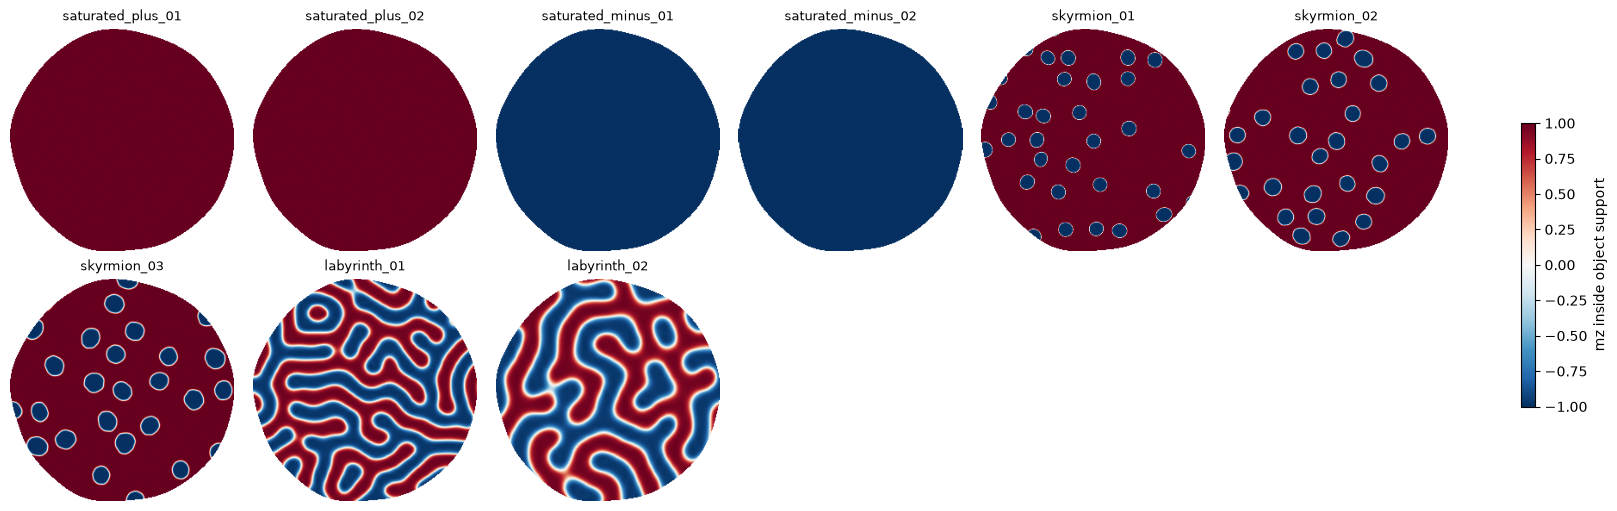

Verified 9 states: {'saturated': 4, 'skyrmion': 3, 'labyrinth': 2}; fixed energy, completion flags, and support dimensions.


In [10]:
if globals().get("state_files"):
    preview_dir = Path(state_files[0]).parent
    # Prefer the saved run declaration when previewing an older dataset.
    from collections import Counter
    manifest_path = preview_dir / "manifest.json"
    expected_specs = (json.loads(manifest_path.read_text())["states"]
                      if manifest_path.exists() else None)
    if expected_specs is not None:
        assert len(state_files) == len(expected_specs), "Selected files do not match the declared run"
        expected_counts = Counter(spec["family"] for spec in expected_specs)
        expected_names = Counter(spec["name"] for spec in expected_specs)
    columns = min(6, len(state_files))
    rows = (len(state_files) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(2.7 * columns, 2.5 * rows),
                             squeeze=False, constrained_layout=True)
    energies = []
    counts = Counter()
    names = Counter()
    for ax, path in zip(axes.ravel(), state_files):
        with h5py.File(path, "r") as f:
            assert f.attrs["complete"]
            energies.append(f.attrs["energy_eV"])
            counts[f.attrs["family"]] += 1
            names[f.attrs["state_name"]] += 1
            mz = f["magnetization/mz"][:]
            support = f["masks/object_support_mask"][:].astype(bool)
            assert support.shape == mz.shape and support.any()
            assert f["support_mask"].shape == f["holograms/detected/CR"].shape[-2:]
            yy, xx = np.nonzero(support)
            crop = (slice(yy.min(), yy.max() + 1), slice(xx.min(), xx.max() + 1))
            im = ax.imshow(np.ma.array(mz, mask=~support)[crop], cmap="RdBu_r", vmin=-1, vmax=1)
            ax.set_title(f.attrs["state_name"], fontsize=9)
            ax.set_axis_off()
    assert np.all(np.asarray(energies) == energies[0])
    if expected_specs is not None:
        assert counts == expected_counts, "State families do not match the declared run"
        assert names == expected_names, "Missing or duplicate states in selected files"
    else:
        assert all(count == 1 for count in names.values()), "Duplicate states in selected files"
    for ax in axes.ravel()[len(state_files):]:
        ax.set_axis_off()
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label="mz inside object support")
    fig.savefig(preview_dir / "magnetic_states.png", dpi=160)
    plt.show()
    print(f"Verified {len(state_files)} states: {dict(counts)}; fixed energy, completion flags, and support dimensions.")
else:
    print("No state files selected. Generate the dataset or set state_files to an earlier run.")


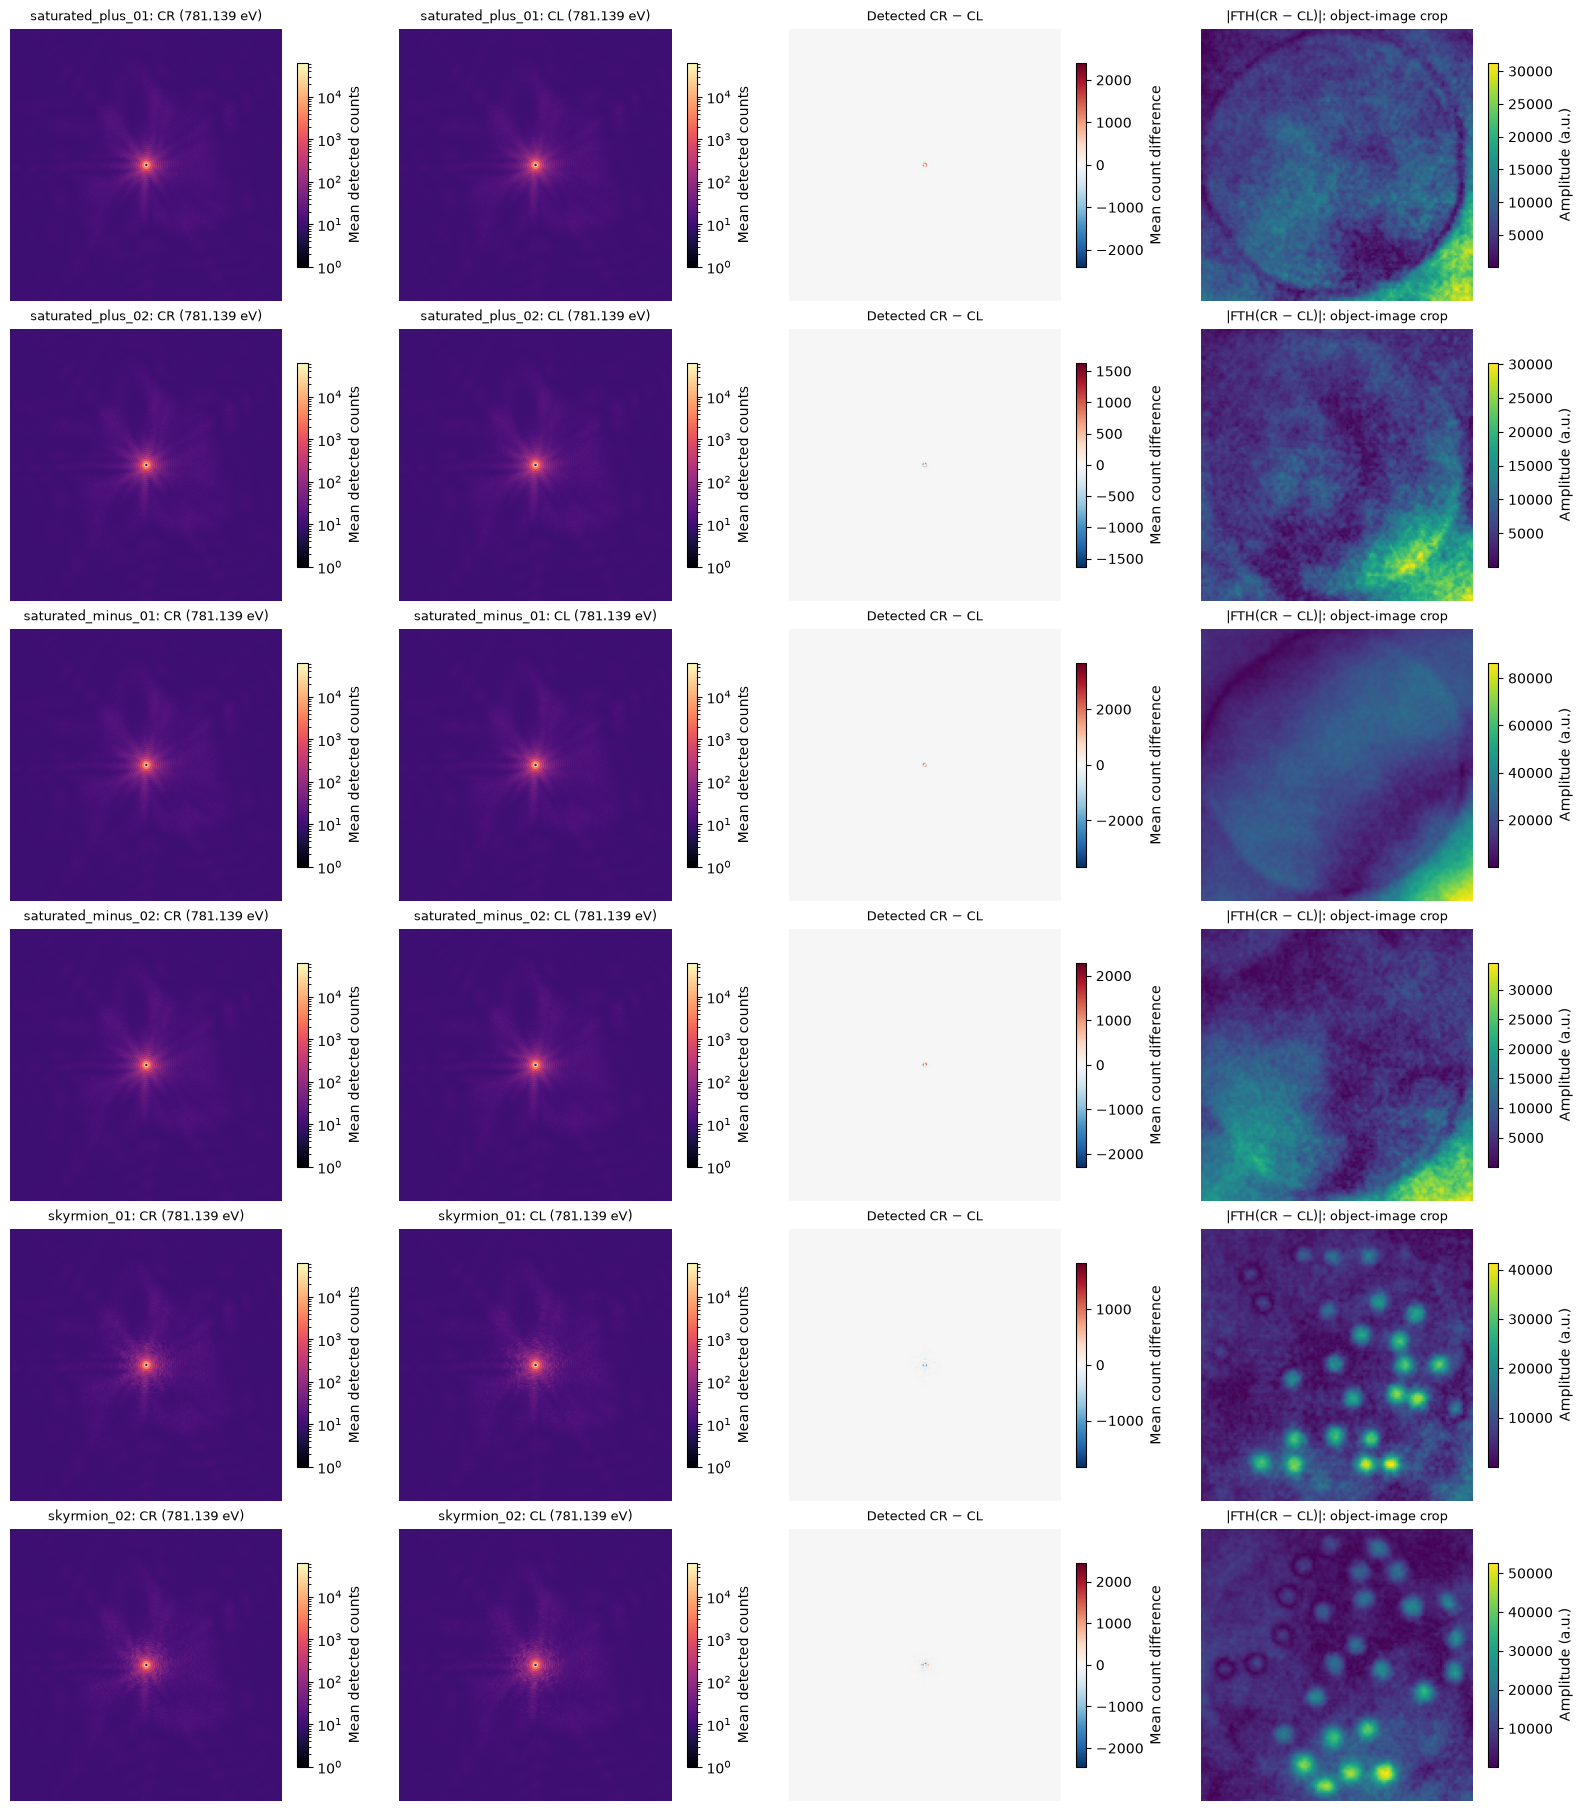

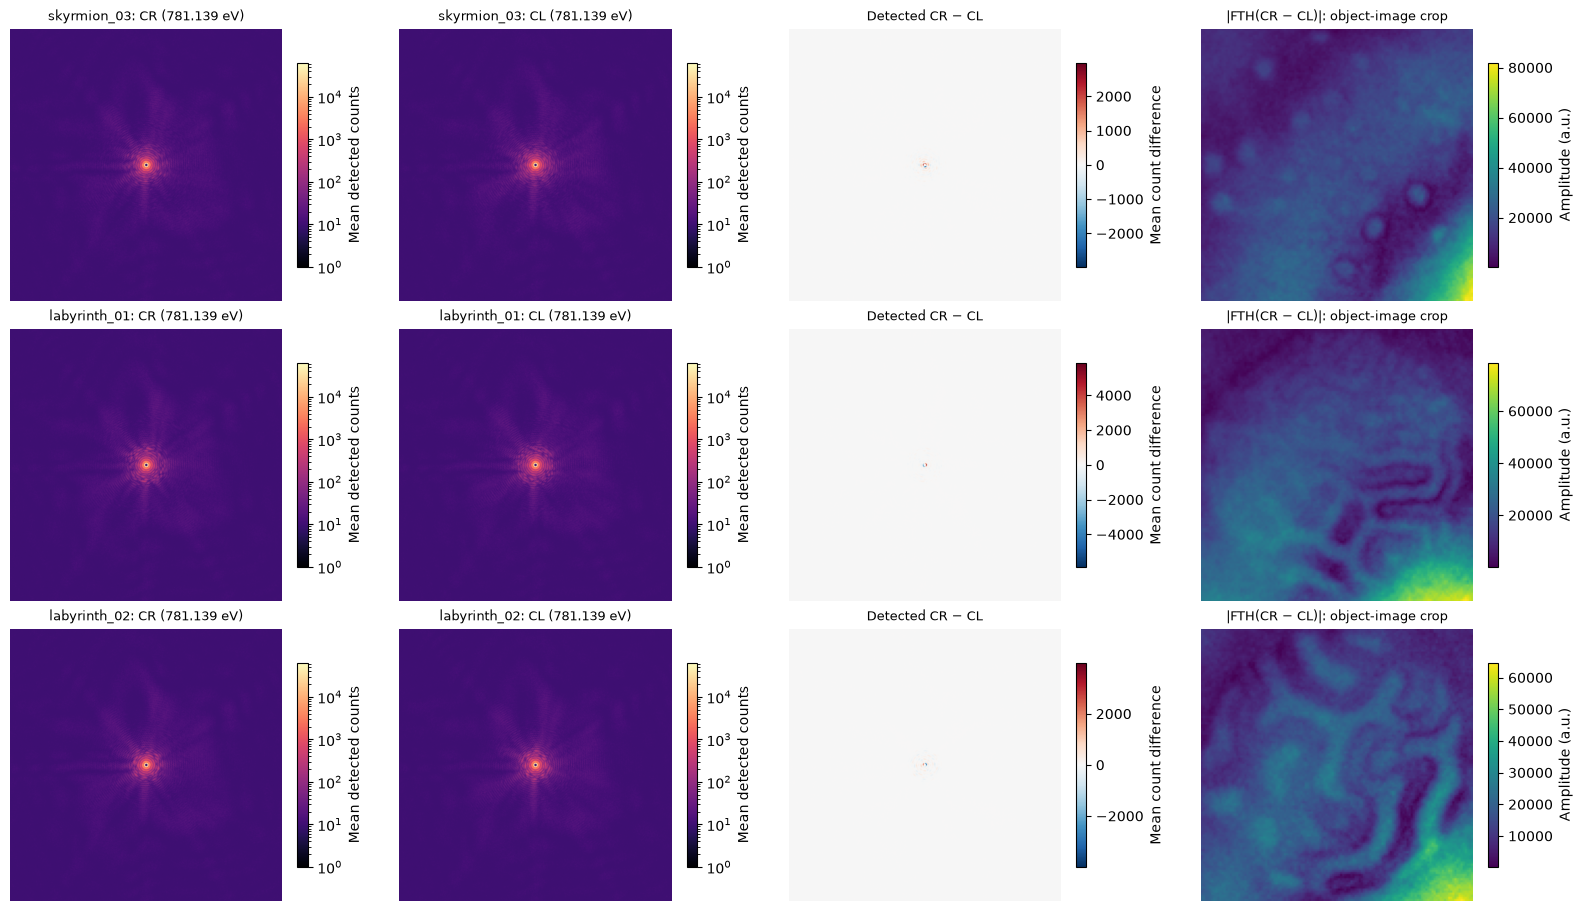

In [11]:
from matplotlib.colors import LogNorm

# Six states per figure keeps measurement previews readable.
if globals().get("state_files"):
    preview_dir = Path(state_files[0]).parent
    for start in range(0, len(state_files), 6):
        batch = state_files[start:start + 6]
        fig, axes = plt.subplots(len(batch), 4, figsize=(16, 3 * len(batch)),
                                 squeeze=False, constrained_layout=True)
        for row, path in enumerate(batch):
            with h5py.File(path, "r") as f:
                if not f.attrs.get("complete", False):
                    raise ValueError(f"Incomplete state file: {path}")
                cr = frame_average(f["holograms/detected/CR"])
                cl = frame_average(f["holograms/detected/CL"])
                difference = cr - cl
                y0, y1, x0, x1 = map(int, f.attrs["recon_oh_slices"])
                # FFT is linear: reconstructing the mean difference equals
                # averaging the saved frame reconstructions, without reading them.
                reconstruction = np.abs(fth_reconstruct(difference)[y0:y1, x0:x1])
                state_name = f.attrs["state_name"]
                saved_energy = float(f.attrs["energy_eV"])
            count_max = max(float(cr.max()), float(cl.max()), 1.0)
            count_norm = LogNorm(vmin=1.0, vmax=max(count_max, 1.01))
            for col, (label, counts_image) in enumerate((("CR", cr), ("CL", cl))):
                im = axes[row, col].imshow(np.ma.masked_less_equal(counts_image, 0),
                                           cmap="magma", norm=count_norm)
                axes[row, col].set_title(f"{state_name}: {label} ({saved_energy:.3f} eV)", fontsize=9)
                fig.colorbar(im, ax=axes[row, col], shrink=0.75, label="Mean detected counts")
            limit = max(float(np.max(np.abs(difference))), np.finfo(float).eps)
            im = axes[row, 2].imshow(difference, cmap="RdBu_r", vmin=-limit, vmax=limit)
            axes[row, 2].set_title("Detected CR − CL", fontsize=9)
            fig.colorbar(im, ax=axes[row, 2], shrink=0.75, label="Mean count difference")
            im = axes[row, 3].imshow(reconstruction, cmap="viridis")
            axes[row, 3].set_title("|FTH(CR − CL)|: object-image crop", fontsize=9)
            fig.colorbar(im, ax=axes[row, 3], shrink=0.75, label="Amplitude (a.u.)")
            for ax in axes[row]:
                ax.set_axis_off()
            del cr, cl, difference, reconstruction
        fig.savefig(preview_dir / f"detected_results_{start + 1:02d}_{start + len(batch):02d}.png", dpi=160)
        plt.show()
        plt.close(fig)


## Real-space exit waves around the object hole
Plot CR and CL exit-wave amplitude and phase in the saved sample-plane OH crop.
Axes show physical sample coordinates in nanometres. Amplitude limits are shared
between helicities for each state; phase uses the same −π to π scale throughout.
Only the cropped exit waves are read, one state file at a time. PNGs are saved
alongside the HDF5 files.


ValueError: too many values to unpack (expected 2)

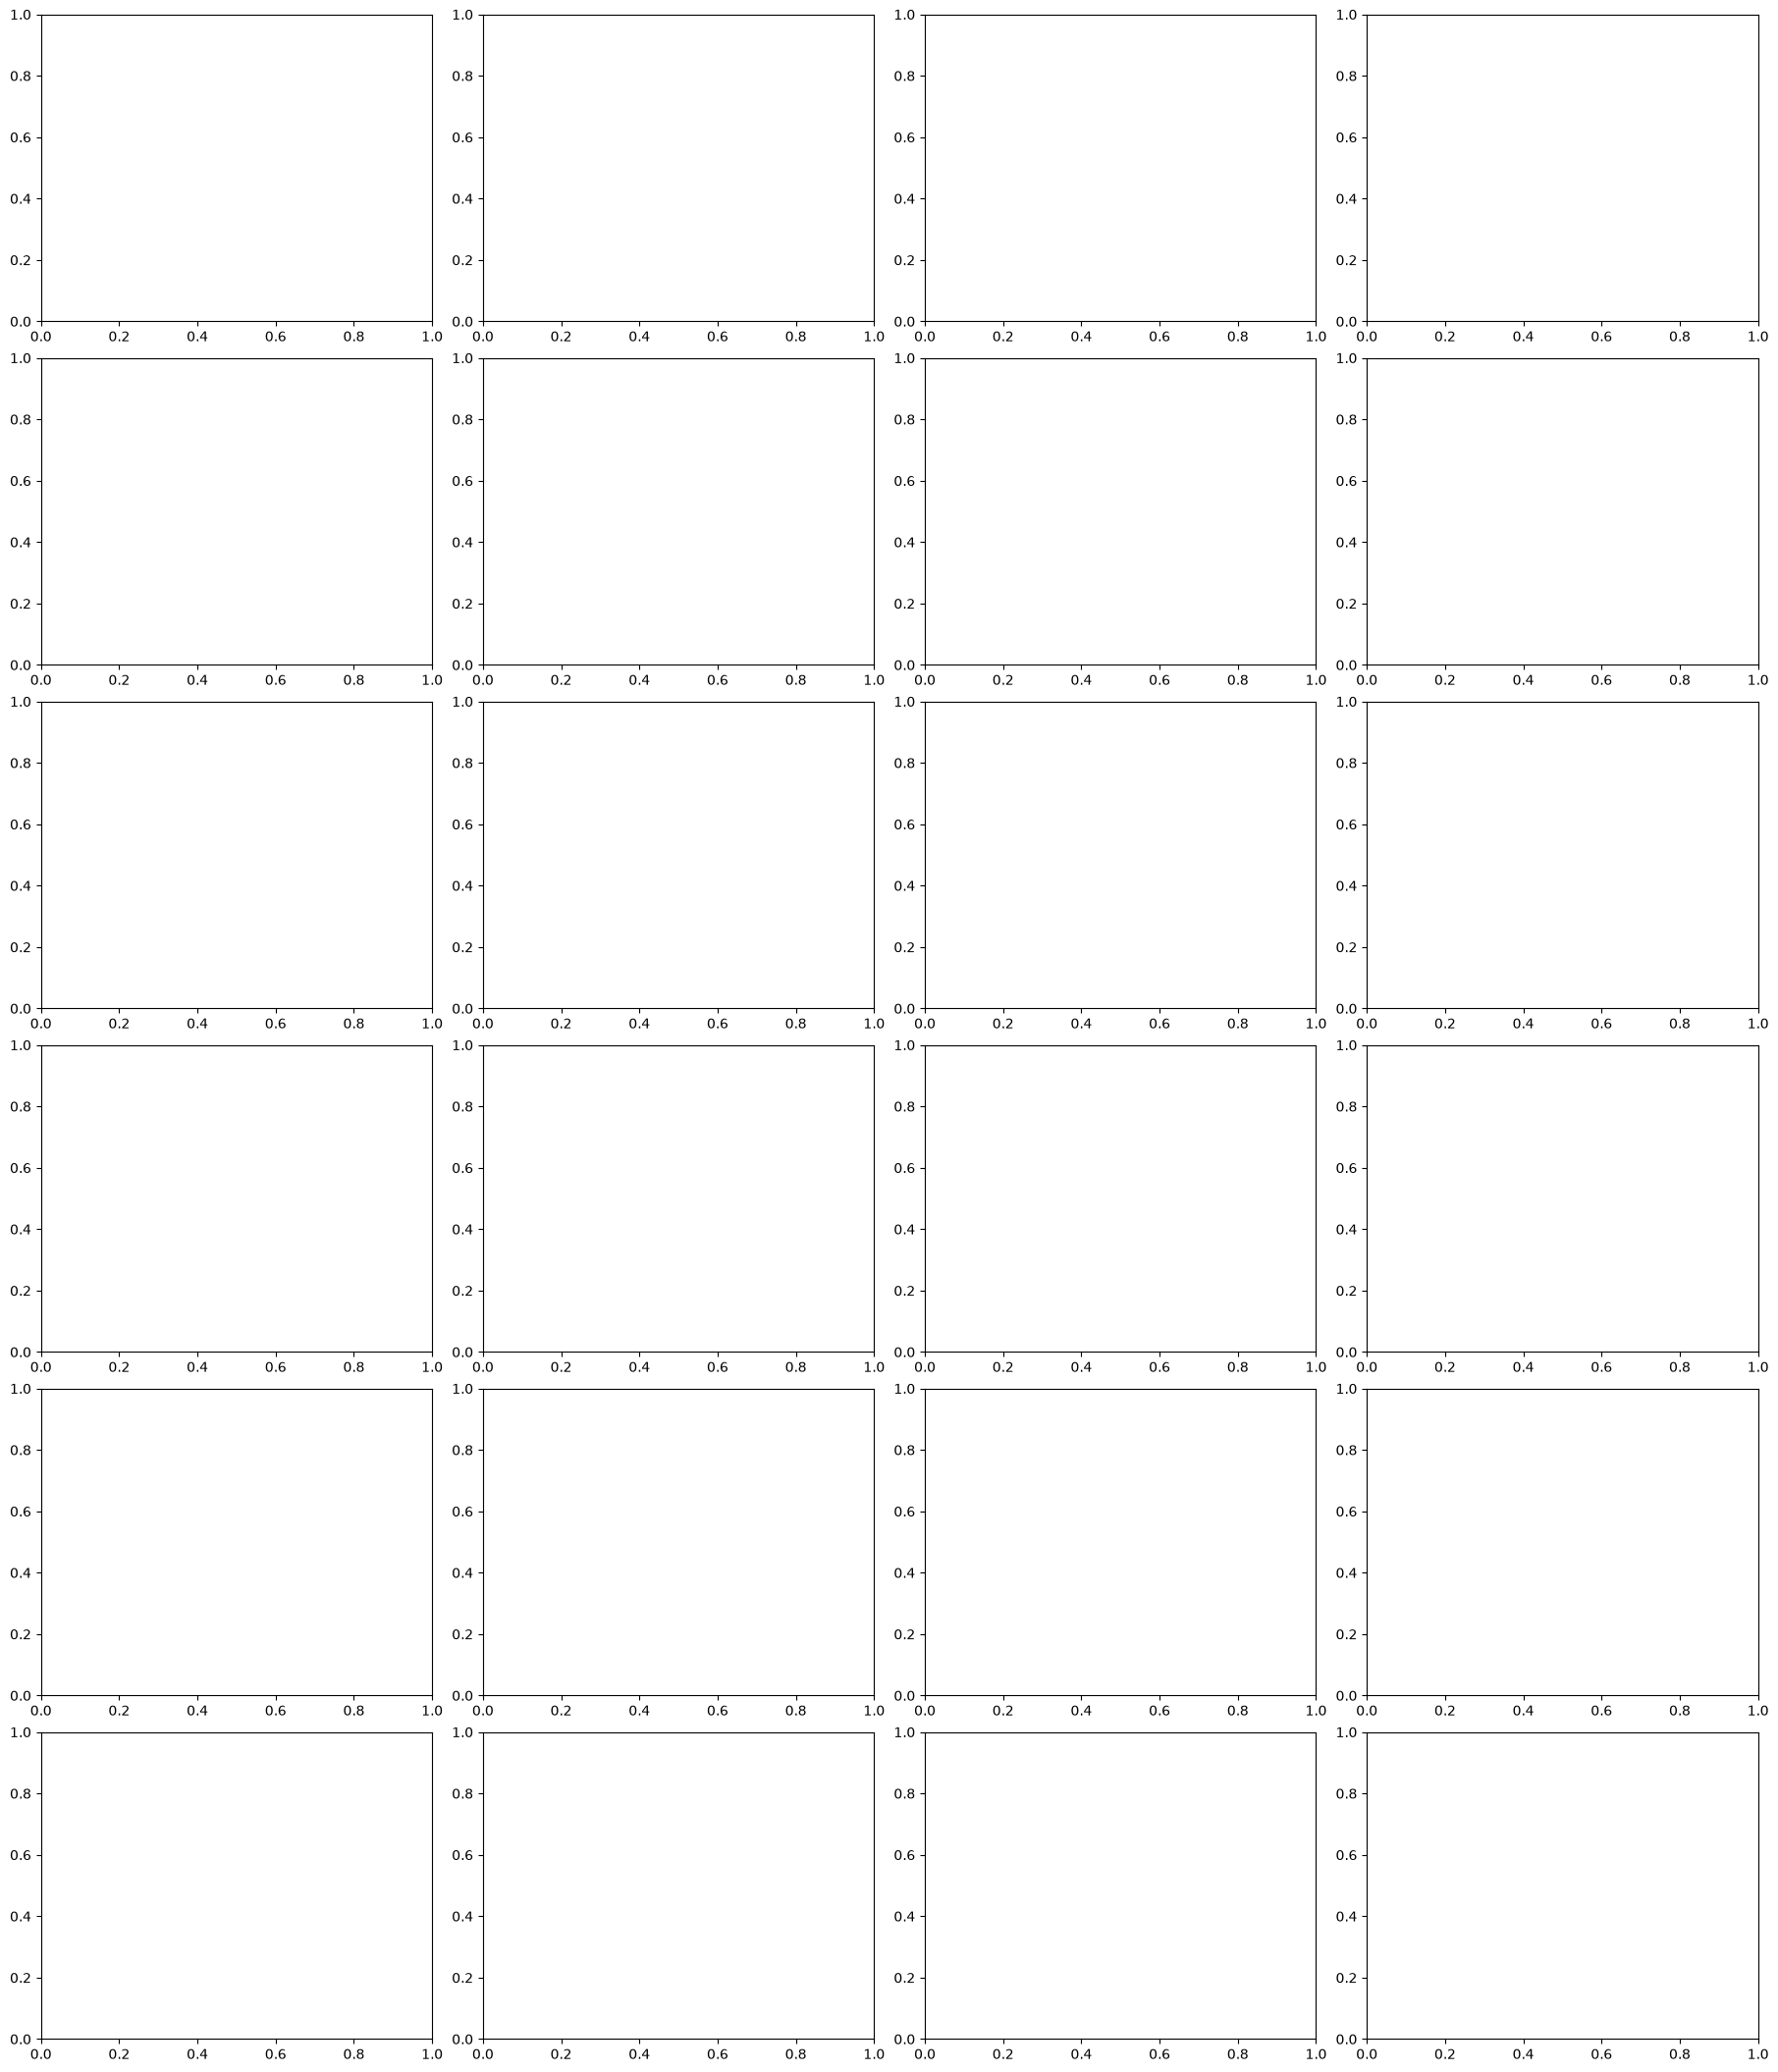

In [12]:
if globals().get("state_files"):
    preview_dir = Path(state_files[0]).parent
    for start in range(0, len(state_files), 6):
        batch = state_files[start:start + 6]
        fig, axes = plt.subplots(len(batch), 4, figsize=(18, 3.5 * len(batch)),
                                 squeeze=False, constrained_layout=True)
        for row, path in enumerate(batch):
            with h5py.File(path, "r") as f:
                if not f.attrs.get("complete", False):
                    raise ValueError(f"Incomplete state file: {path}")
                y0, y1, x0, x1 = map(int, f.attrs["sample_oh_slices"])
                waves = [f[f"holograms/exit_waves/{pol}"][y0:y1, x0:x1]
                         for pol in ("CR", "CL")]
                ny, nx = f["holograms/exit_waves/CR"].shape
                pixel_nm = float(f.attrs["sample_pixel_size_m"]) * 1e9
                # Pixel-edge coordinates follow the saved sample-grid origin.
                extent = [(x0 - nx / 2 - 0.5) * pixel_nm,
                          (x1 - nx / 2 - 0.5) * pixel_nm,
                          (y1 - ny / 2 - 0.5) * pixel_nm,
                          (y0 - ny / 2 - 0.5) * pixel_nm]
                state_name = f.attrs["state_name"]
            amplitude_max = max(float(np.abs(wave).max()) for wave in waves)
            amplitude_max = max(amplitude_max, np.finfo(float).eps)
            for pol_index, (pol, wave) in enumerate(zip(("CR", "CL"), waves)):
                amplitude_ax, phase_ax = axes[row, 2 * pol_index:2 * pol_index + 2]
                im = amplitude_ax.imshow(np.abs(wave), origin="upper", extent=extent,
                                         cmap="viridis", vmin=0, vmax=amplitude_max)
                amplitude_ax.set_title(f"{state_name}: {pol} amplitude", fontsize=9)
                fig.colorbar(im, ax=amplitude_ax, shrink=0.75, label="|Exit wave| (a.u.)")
                im = phase_ax.imshow(np.angle(wave), origin="upper", extent=extent,
                                     cmap="twilight", vmin=-np.pi, vmax=np.pi)
                phase_ax.set_title(f"{state_name}: {pol} phase", fontsize=9)
                fig.colorbar(im, ax=phase_ax, shrink=0.75, label="Phase (rad)")
            for ax in axes[row]:
                ax.set_xlabel("x (nm)")
                ax.set_ylabel("y (nm)")
            del waves, wave
        fig.savefig(preview_dir / f"exit_waves_OH_{start + 1:02d}_{start + len(batch):02d}.png", dpi=160)
        plt.show()
        plt.close(fig)
